In [ ]:
py -m pip install scikit-learn

Level 2 Task 3: Clustering Analysis (K-Means)

The objective of this task is to group similar observations within the Iris dataset using the K-Means clustering algorithm. The dataset will be standardized, the optimal number of clusters will be determined using the elbow method, and the resulting clusters will be visualized using a two-dimensional scatter plot.

Tools Used
Python
Scikit-learn
Matplotlib
Seaborn

In [1]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

The Iris dataset contains measurements of iris flowers, including sepal length, sepal width, petal length, and petal width. These features are used to identify natural groupings within the dataset through clustering analysis.

In [2]:
df = pd.read_csv("1) iris.csv")

df.head()


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
X = df.drop('species', axis=1)

X.head()

,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


The dataset was standardized using StandardScaler to ensure that all features contribute equally to the clustering process. This prevents variables with larger values from having a greater influence on the clustering results.

In [4]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

The elbow method was used to determine the optimal number of clusters by calculating the Within-Cluster Sum of Squares (WCSS) for different values of K.

In [5]:
wcss = []

for i in range(1, 11):

    kmeans = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    wcss.append(kmeans.inertia_)

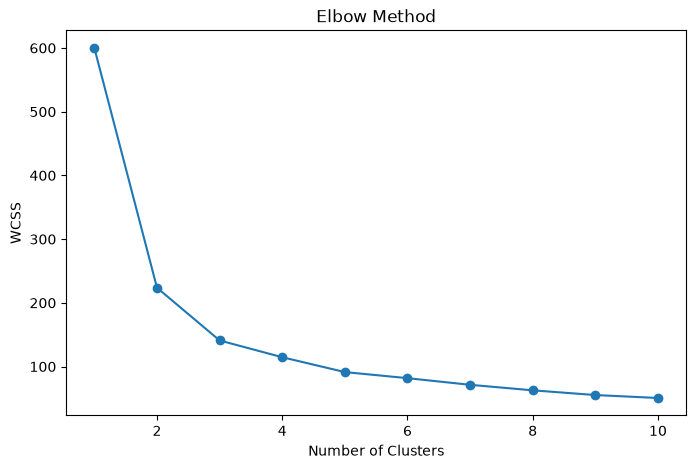

In [6]:
plt.figure(figsize=(8,5))

plt.plot(range(1,11), wcss, marker="o")

plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")

plt.show()

The elbow plot shows a steep decrease in WCSS values from 1 to 3 clusters, after which the rate of decrease becomes much smaller.

This indicates that adding more than three clusters provides only limited improvement in cluster compactness.

Therefore, K = 3 was selected as the optimal number of clusters for the K-Means model.

In [8]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)

df["Cluster"] = clusters

In [9]:
df.head()


,sepal_length,sepal_width,petal_length,petal_width,species,Cluster
0,5.1,3.5,1.4,0.2,setosa,1
1,4.9,3.0,1.4,0.2,setosa,1
2,4.7,3.2,1.3,0.2,setosa,1
3,4.6,3.1,1.5,0.2,setosa,1
4,5.0,3.6,1.4,0.2,setosa,1


The K-Means algorithm was applied using the selected number of clusters. A two-dimensional scatter plot was created to visualize the resulting clusters.

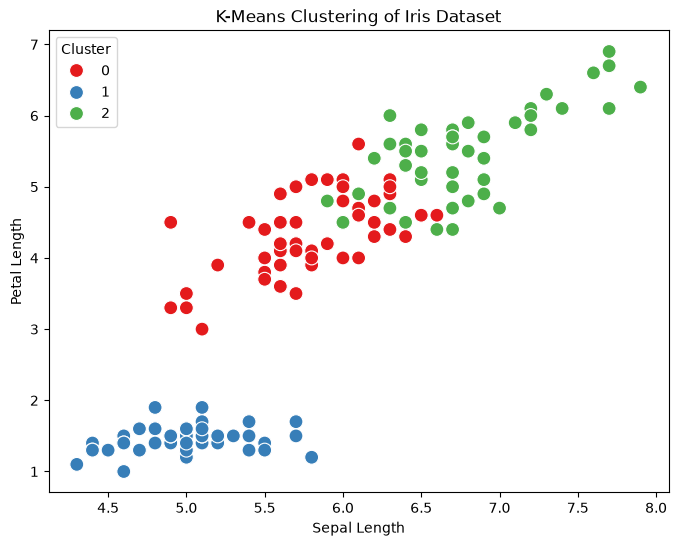

In [10]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    x='sepal_length',
    y='petal_length',
    hue='Cluster',
    data=df,
    palette='Set1',
    s=100
)

plt.title("K-Means Clustering of Iris Dataset")
plt.xlabel("Sepal Length")
plt.ylabel("Petal Length")

plt.show()

The K-Means algorithm successfully grouped the Iris dataset into three clusters based on flower measurements.

Cluster 1 is clearly separated from the others.
Clusters 0 and 2 show slight overlap but remain distinguishable.
The clusters reveal natural groupings within the dataset.

The K-Means model effectively identified patterns in the Iris dataset and grouped similar observations into meaningful clusters.

In [11]:
df["Cluster"].value_counts()

Cluster
0    53
1    50
2    47
Name: count, dtype: int64

The K-Means algorithm grouped the 150 observations into three clusters:

Cluster 0: 53 observations
Cluster 1: 50 observations
Cluster 2: 47 observations

The clusters are relatively balanced in size, indicating that the algorithm successfully distributed similar observations into meaningful groups.

K-Means clustering was successfully implemented on the Iris dataset.

Key Activities Completed
Standardized the dataset using StandardScaler.
Determined the optimal number of clusters using the elbow method.
Applied the K-Means clustering algorithm.
Visualized the resulting clusters using a two-dimensional scatter plot.
The analysis successfully identified natural groupings within the dataset and demonstrated the effectiveness of unsupervised machine learning techniques.